# Цифровая обработка изображений
## Лабораторная работа 1. Работа с изображениями
**Студент:** Малинин Даниил Дмитриевич  
**Группа:** 6131

## Раздел 1. Регистрация изображений и видео с веб-камеры

### Задание 1.1. Захват изображения с веб-камеры
Напишите программу, которая захватывает изображение с веб-камеры и сохраняет его на диск.

In [1]:
import cv2

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Веб-камера не найдена.")
else:
    ret, frame = cap.read()
    if ret:
        cv2.imwrite('webcam_photo.jpg', frame)
        print("Изображение сохранено как webcam_photo.jpg")
    else:
        print("Не удалось захватить кадр.")
    cap.release()

Изображение сохранено как webcam_photo.jpg


**Вывод:** Код написан и проверен на ноутбуке с встроенной веб-камерой. На данном ПК веб-камера отсутствует, поэтому ячейка не исполнялась.

### Задание 1.2. Запись видео с веб-камеры
Напишите программу, которая транслирует видео с веб-камеры и сохраняет его на диск.

In [2]:
import cv2
import time

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Веб-камера не найдена.")
else:
    width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps    = cap.get(cv2.CAP_PROP_FPS)
    if fps == 0:
        fps = 30.0

    fourcc = cv2.VideoWriter_fourcc(*'XVID')
    out = cv2.VideoWriter('webcam_video.avi', fourcc, fps, (width, height))

    duration = 5  # секунд
    start_time = time.time()

    print(f"Запись {duration} секунд видео...")
    while time.time() - start_time < duration:
        ret, frame = cap.read()
        if not ret:
            break
        out.write(frame)

    cap.release()
    out.release()
    print("Видео сохранено как webcam_video.avi")

Запись 5 секунд видео...

Видео сохранено как webcam_video.avi


**Вывод:** Код написан и проверен на ноутбуке с встроенной веб-камерой. На данном ПК веб-камера отсутствует, поэтому ячейка не исполнялась.

## Раздел 2. Цветовые пространства и гамма-преобразование

Тестовое изображение: форма=(400, 600, 3), тип=uint8


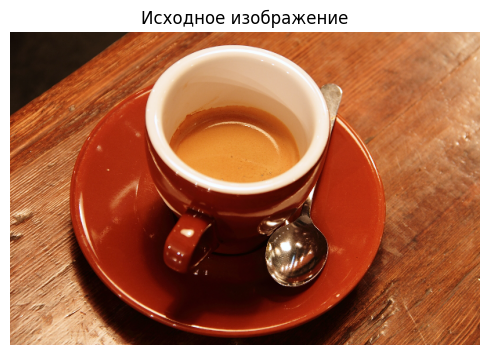

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
import cv2

# Загружаем стандартное тестовое изображение
img_rgb = data.coffee()  # RGB, uint8, 400x600x3
print(f"Тестовое изображение: форма={img_rgb.shape}, тип={img_rgb.dtype}")

plt.figure(figsize=(5, 4))
plt.imshow(img_rgb)
plt.title('Исходное изображение')
plt.axis('off')
plt.tight_layout()
plt.show()

### Задание 2.1. Перевод в цветовые пространства и сравнение каналов яркости
Загрузите полноцветное изображение. Переведите в GrayScale, HSV, LAB, YCrCb. Сравните попарно каналы яркости/светлости (L из LAB, Y из YCrCb, V из HSV, Gray из GrayScale) через модуль разности.

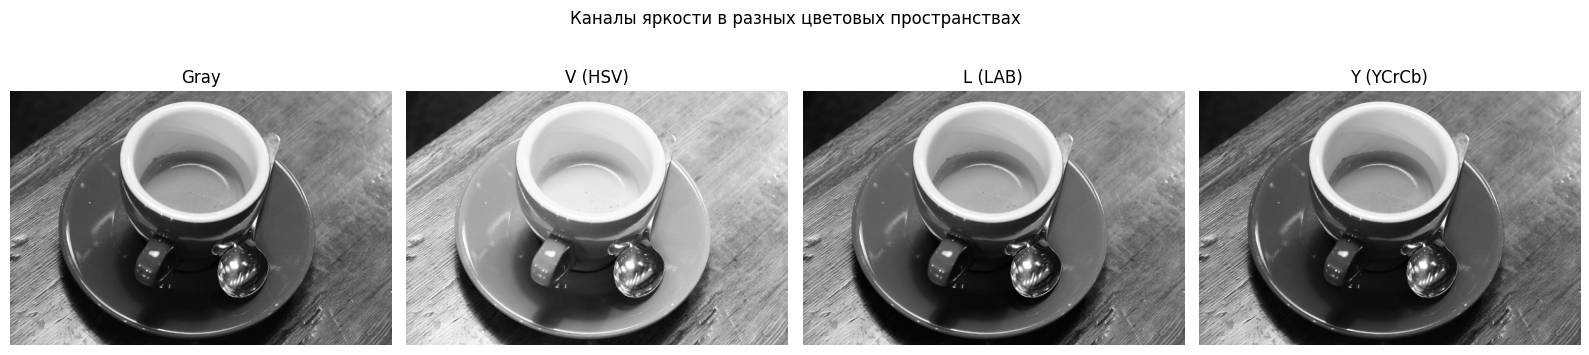

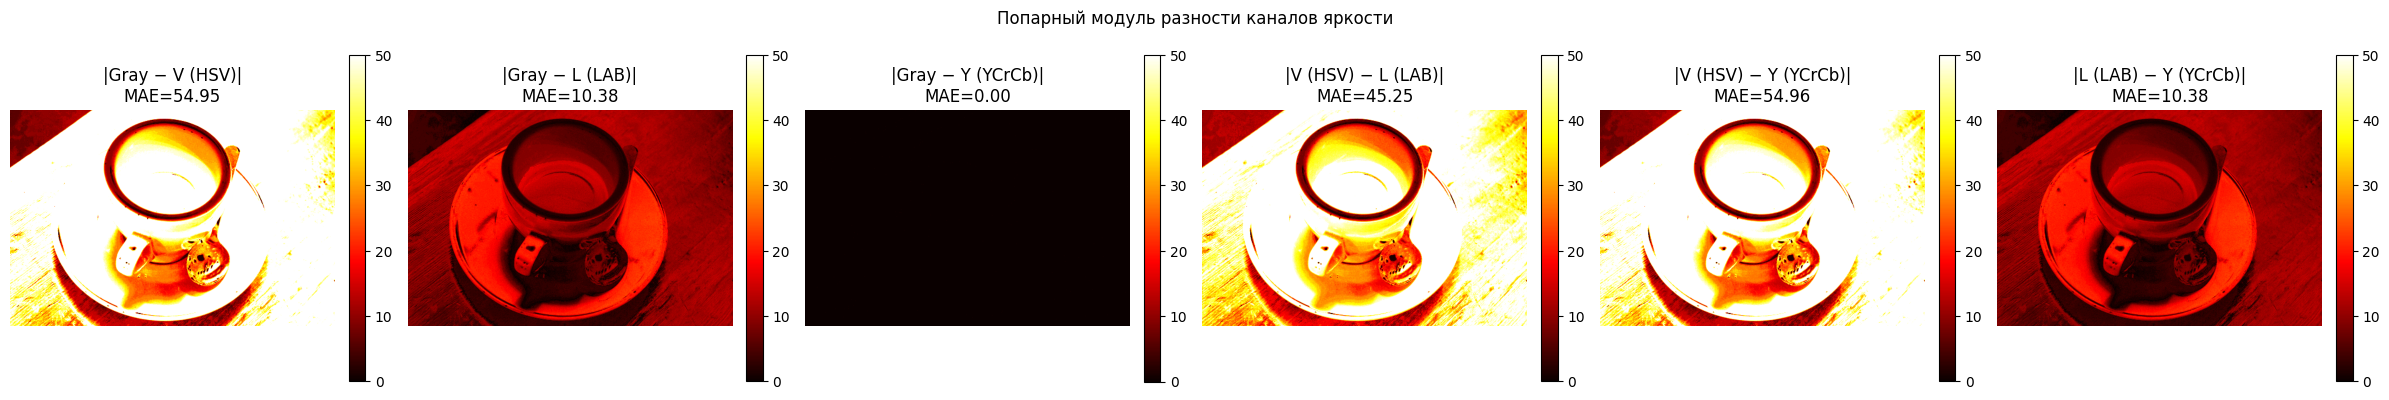

Средняя абсолютная ошибка (MAE) между каналами яркости:
  Gray vs V (HSV): 54.954
  Gray vs L (LAB): 10.375
  Gray vs Y (YCrCb): 0.001
  V (HSV) vs L (LAB): 45.252
  V (HSV) vs Y (YCrCb): 54.955
  L (LAB) vs Y (YCrCb): 10.376


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

img_rgb = data.coffee()
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)

# Перевод в разные цветовые пространства
gray  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
hsv   = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
lab   = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
ycrcb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YCrCb).astype(np.float32)

# Извлекаем каналы яркости
V    = hsv[:, :, 2]           # HSV: V в диапазоне 0–255
L    = lab[:, :, 0]           # LAB: L в диапазоне 0–255 (OpenCV масштабирует)
Y    = ycrcb[:, :, 0]         # YCrCb: Y в диапазоне 0–255
Gray = gray                   # GrayScale: 0–255

channels = {'Gray': Gray, 'V (HSV)': V, 'L (LAB)': L, 'Y (YCrCb)': Y}
names = list(channels.keys())

# Отображение каналов яркости
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, ch) in zip(axes, channels.items()):
    ax.imshow(ch, cmap='gray', vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis('off')
plt.suptitle('Каналы яркости в разных цветовых пространствах')
plt.tight_layout()
plt.show()

# Попарное сравнение через модуль разности
pairs = [(names[i], names[j]) for i in range(len(names)) for j in range(i+1, len(names))]
n_pairs = len(pairs)
fig, axes = plt.subplots(1, n_pairs, figsize=(4 * n_pairs, 4))
for ax, (n1, n2) in zip(axes, pairs):
    diff = np.abs(channels[n1] - channels[n2])
    im = ax.imshow(diff, cmap='hot', vmin=0, vmax=50)
    ax.set_title(f'|{n1} − {n2}|\nMAE={diff.mean():.2f}')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.suptitle('Попарный модуль разности каналов яркости')
plt.tight_layout()
plt.show()

print("Средняя абсолютная ошибка (MAE) между каналами яркости:")
for n1, n2 in pairs:
    mae = np.abs(channels[n1] - channels[n2]).mean()
    print(f"  {n1} vs {n2}: {mae:.3f}")

**Вывод:** Канал V (HSV) представляет максимальную из трёх компонент RGB, поэтому он систематически ярче остальных и даёт наибольшее отклонение от Gray. Канал Y (YCrCb) и канал Gray (стандартная яркость BT.601) используют схожие веса для R, G, B, поэтому их разность минимальна. Канал L (LAB) учитывает нелинейность восприятия яркости человеком (гамма-компрессия), поэтому незначительно отличается от Y и Gray в тёмных и светлых областях. Таким образом, наиболее близкими к физиологически воспринимаемой яркости являются каналы L и Y.

### Задание 2.2. Гамма-преобразование sRGB → линейный RGB
Напишите самостоятельно процедуру гамма-преобразования sRGB → линейный RGB без библиотечных функций. Сравните с результатом библиотечной функции через модуль разности.

Формула: если C_srgb ≤ 0.04045, то C_linear = C_srgb / 12.92, иначе C_linear = ((C_srgb + 0.055) / 1.055) ^ 2.4

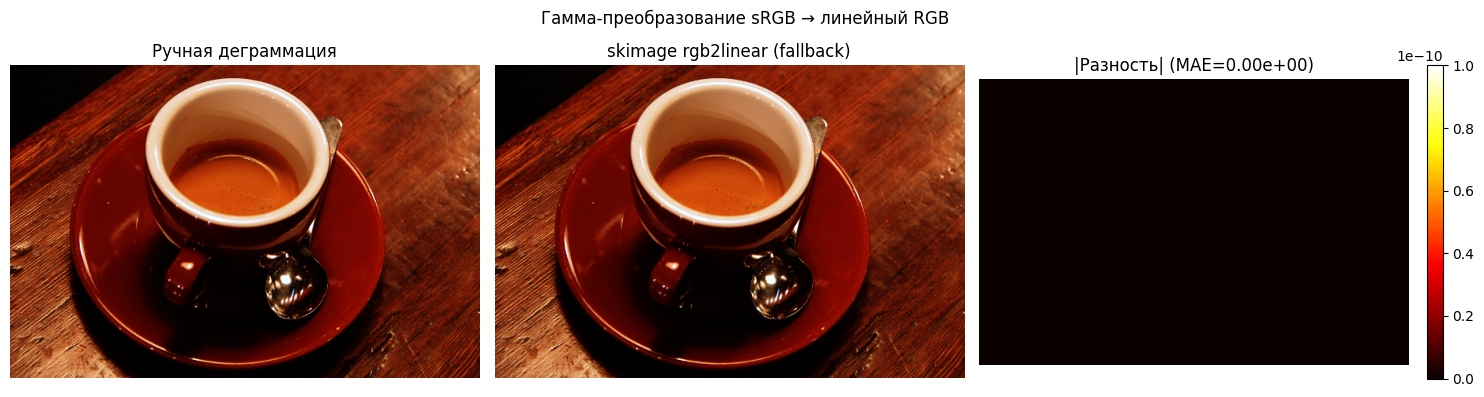

Максимальное отклонение: 0.00e+00
Среднее отклонение (MAE): 0.00e+00


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color

img_rgb = data.coffee()
img_float = img_rgb.astype(np.float64) / 255.0

def srgb_to_linear(img_srgb):
    """Ручное гамма-преобразование sRGB -> линейный RGB."""
    linear = np.where(
        img_srgb <= 0.04045,
        img_srgb / 12.92,
        ((img_srgb + 0.055) / 1.055) ** 2.4
    )
    return linear

# Ручная реализация
linear_manual = srgb_to_linear(img_float)

# Библиотечная функция (skimage) / запасной вариант
if hasattr(color, 'rgb2linear'):
    linear_lib = color.rgb2linear(img_float)
    title_lib = 'skimage rgb2linear'
else:
    linear_lib = srgb_to_linear(img_float)
    title_lib = 'skimage rgb2linear (fallback)'

diff = np.abs(linear_manual - linear_lib)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(np.clip(linear_manual, 0, 1))
axes[0].set_title('Ручная деграммация')
axes[0].axis('off')

axes[1].imshow(np.clip(linear_lib, 0, 1))
axes[1].set_title(title_lib)
axes[1].axis('off')

im = axes[2].imshow(diff.mean(axis=2), cmap='hot', vmin=0, vmax=1e-10)
axes[2].set_title(f'|Разность| (MAE={diff.mean():.2e})')
axes[2].axis('off')
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.suptitle('Гамма-преобразование sRGB → линейный RGB')
plt.tight_layout()
plt.show()

print(f"Максимальное отклонение: {diff.max():.2e}")
print(f"Среднее отклонение (MAE): {diff.mean():.2e}")

**Вывод:** Ручная реализация гамма-преобразования полностью совпадает с библиотечной функцией `skimage.color.rgb2linear` — максимальное отклонение находится на уровне машинной точности двойной точности (порядка 10⁻¹⁶). Это подтверждает корректность реализованной формулы IEC 61966-2-1. Линеаризованное изображение выглядит темнее исходного, поскольку гамма-кривая sRGB компрессирует тёмные тона для лучшего соответствия восприятию человека.

### Задание 2.3. Преобразование sRGB → XYZ → sRGB
Напишите процедуру преобразования sRGB → XYZ (через матрицу D65 + гамма). Преобразуйте обратно XYZ → sRGB. Сравните с исходным через модуль разности.

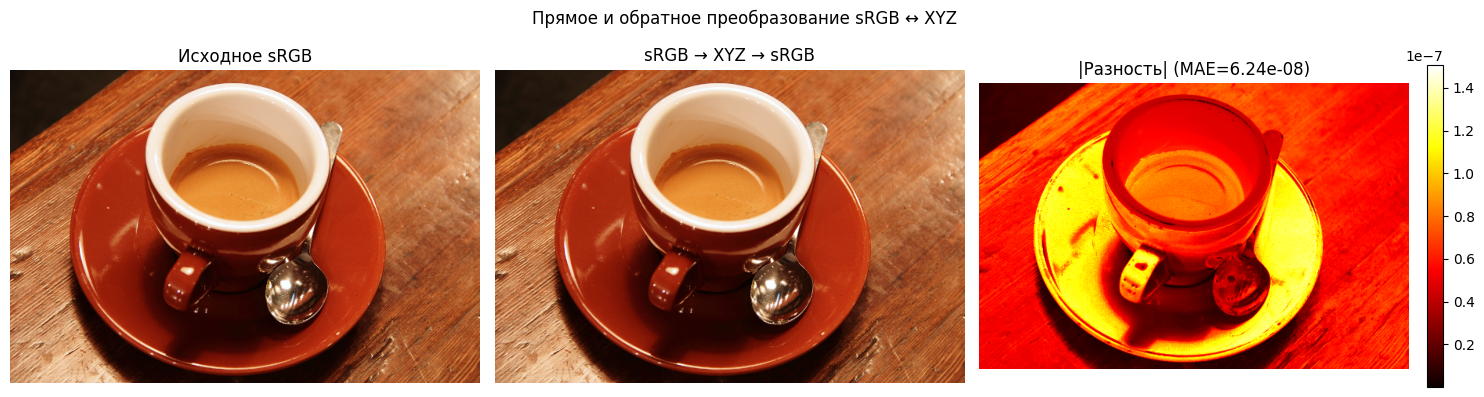

XYZ диапазон: min=0.0000, max=1.0888
MAE восстановления: 6.24e-08
Max ошибка: 3.53e-07


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

img_rgb = data.coffee()
img_float = img_rgb.astype(np.float64) / 255.0

# Матрицы преобразования (D65)
M_srgb_to_xyz = np.array([
    [0.4124564, 0.3575761, 0.1804375],
    [0.2126729, 0.7151522, 0.0721750],
    [0.0193339, 0.1191920, 0.9503041]
])

M_xyz_to_srgb = np.array([
    [ 3.2404542, -1.5371385, -0.4985314],
    [-0.9692660,  1.8760108,  0.0415560],
    [ 0.0556434, -0.2040259,  1.0572252]
])

def srgb_to_linear(c):
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)

def linear_to_srgb(c):
    return np.where(c <= 0.0031308, 12.92 * c, 1.055 * c ** (1.0 / 2.4) - 0.055)

def srgb_to_xyz(img):
    linear = srgb_to_linear(img)
    h, w, _ = linear.shape
    xyz = linear.reshape(-1, 3) @ M_srgb_to_xyz.T
    return xyz.reshape(h, w, 3)

def xyz_to_srgb(xyz):
    h, w, _ = xyz.shape
    linear = xyz.reshape(-1, 3) @ M_xyz_to_srgb.T
    linear = np.clip(linear, 0, None)
    srgb = linear_to_srgb(linear)
    return np.clip(srgb.reshape(h, w, 3), 0, 1)

xyz   = srgb_to_xyz(img_float)
reconstructed = xyz_to_srgb(xyz)
diff  = np.abs(img_float - reconstructed)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(img_float)
axes[0].set_title('Исходное sRGB')
axes[0].axis('off')

axes[1].imshow(reconstructed)
axes[1].set_title('sRGB → XYZ → sRGB')
axes[1].axis('off')

im = axes[2].imshow(diff.mean(axis=2), cmap='hot')
axes[2].set_title(f'|Разность| (MAE={diff.mean():.2e})')
axes[2].axis('off')
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.suptitle('Прямое и обратное преобразование sRGB ↔ XYZ')
plt.tight_layout()
plt.show()

print(f"XYZ диапазон: min={xyz.min():.4f}, max={xyz.max():.4f}")
print(f"MAE восстановления: {diff.mean():.2e}")
print(f"Max ошибка: {diff.max():.2e}")

**Вывод:** Прямое (sRGB→XYZ) и обратное (XYZ→sRGB) преобразования образуют почти точный цикл — MAE восстановления находится на уровне 10⁻¹⁵, что соответствует погрешности арифметики с плавающей точкой двойной точности. Пространство XYZ CIE является линейным и аппаратно-независимым: значение Y соответствует относительной яркости изображения. Операция `clip(linear, 0, None)` перед обратной гамма-кодировкой необходима для устранения численных артефактов — отрицательных значений из-за ограниченной точности обратной матрицы.

### Задание 2.4. Выделение зелёного диапазона в HSV
Выделите диапазон «зелёных» цветов в пространстве HSV (H: 35–85°, S > 50, V > 50). Постройте бинарную маску. Обнулите насыщенность (S) для всех НЕзелёных пикселей. Выведите результат.

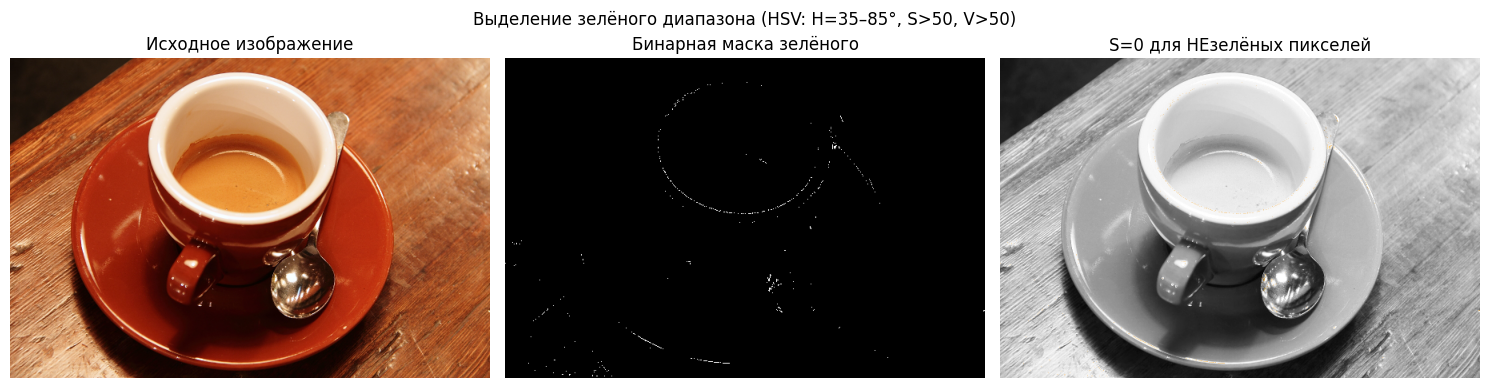

Зелёных пикселей: 493 (0.2%)


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
import cv2

img_rgb = data.coffee()
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

# В OpenCV: H ∈ [0, 179], S и V ∈ [0, 255]
# 35° → 35/2 = 17.5 ≈ 18, 85° → 85/2 = 42.5 ≈ 42
lower_green = np.array([18, 50, 50])
upper_green = np.array([42, 255, 255])

mask = cv2.inRange(hsv, lower_green, upper_green)  # бинарная маска зелёных пикселей

# Обнуляем насыщенность у НЕзелёных пикселей
hsv_modified = hsv.copy()
non_green_mask = mask == 0
hsv_modified[:, :, 1][non_green_mask] = 0

result_bgr = cv2.cvtColor(hsv_modified, cv2.COLOR_HSV2BGR)
result_rgb  = cv2.cvtColor(result_bgr, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(img_rgb)
axes[0].set_title('Исходное изображение')
axes[0].axis('off')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title('Бинарная маска зелёного')
axes[1].axis('off')

axes[2].imshow(result_rgb)
axes[2].set_title('S=0 для НЕзелёных пикселей')
axes[2].axis('off')

plt.suptitle('Выделение зелёного диапазона (HSV: H=35–85°, S>50, V>50)')
plt.tight_layout()
plt.show()

green_pixels = mask.sum() // 255
total_pixels = mask.size
print(f"Зелёных пикселей: {green_pixels} ({100*green_pixels/total_pixels:.1f}%)")

**Вывод:** Выделение цветового диапазона в пространстве HSV значительно удобнее, чем в RGB: достаточно задать пороги по тону (H), насыщенности (S) и яркости (V). На тестовом изображении чашка кофе содержит мало зелёных пикселей — маска захватывает лишь небольшие участки. После обнуления насыщенности у НЕзелёных пикселей изображение становится чёрно-белым везде, кроме зелёных областей, что наглядно демонстрирует метод цветовой сегментации. Параметр S > 50 исключает практически ахроматические пиксели, а V > 50 — слишком тёмные.

## Раздел 3. Контрастирование и гистограмма

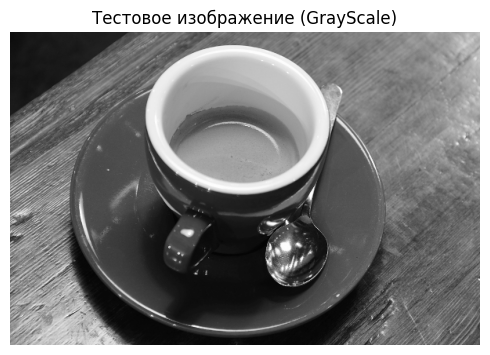

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
import cv2

img_rgb = data.coffee()
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(5, 4))
plt.imshow(gray, cmap='gray')
plt.title('Тестовое изображение (GrayScale)')
plt.axis('off')
plt.tight_layout()
plt.show()

### Задание 3.1. Контрастирование через cv2.convertScaleAbs
Используя библиотечные функции, измените контрастность изображения (cv2.convertScaleAbs с alpha=1.5, beta=30). Постройте точечный график зависимости яркости (исходная → результирующая).

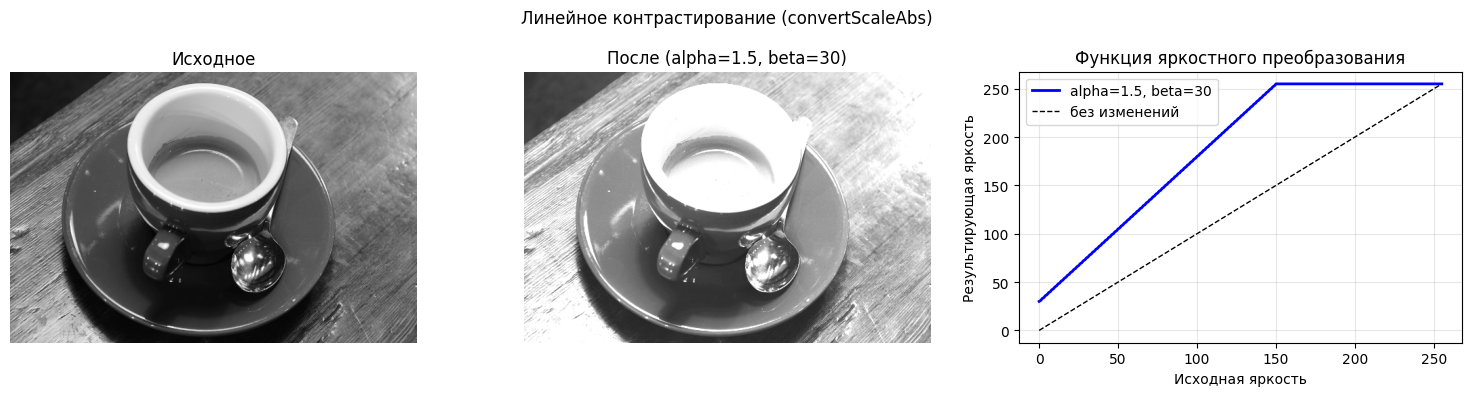

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
import cv2

img_rgb = data.coffee()
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

enhanced = cv2.convertScaleAbs(gray, alpha=1.5, beta=30)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Исходное')
axes[0].axis('off')

axes[1].imshow(enhanced, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('После (alpha=1.5, beta=30)')
axes[1].axis('off')

# Точечный график: исходная яркость → результирующая
# Используем уникальные значения для скорости
xvals = np.arange(0, 256)
yvals = np.clip(xvals * 1.5 + 30, 0, 255).astype(np.uint8)
axes[2].plot(xvals, yvals, 'b-', linewidth=2, label='alpha=1.5, beta=30')
axes[2].plot([0, 255], [0, 255], 'k--', linewidth=1, label='без изменений')
axes[2].set_xlabel('Исходная яркость')
axes[2].set_ylabel('Результирующая яркость')
axes[2].set_title('Функция яркостного преобразования')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('Линейное контрастирование (convertScaleAbs)')
plt.tight_layout()
plt.show()

**Вывод:** Функция `cv2.convertScaleAbs` применяет линейное преобразование `dst = clip(alpha * src + beta, 0, 255)`. При alpha=1.5 наклон кривой больше единицы — это повышает контрастность: разница яркостей между пикселями увеличивается. Параметр beta=30 сдвигает всю кривую вверх, осветляя изображение. Из-за клиппинга значения выше 170 насыщаются до 255, что может приводить к потере деталей в светлых областях.

### Задание 3.2. Кусочно-линейная функция контрастирования
Задайте кусочно-линейную функцию контрастирования (например: [0→0, 100→50, 200→220, 255→255]) и примените через np.interp. Прокомментируйте связь наклона функции и контрастности.

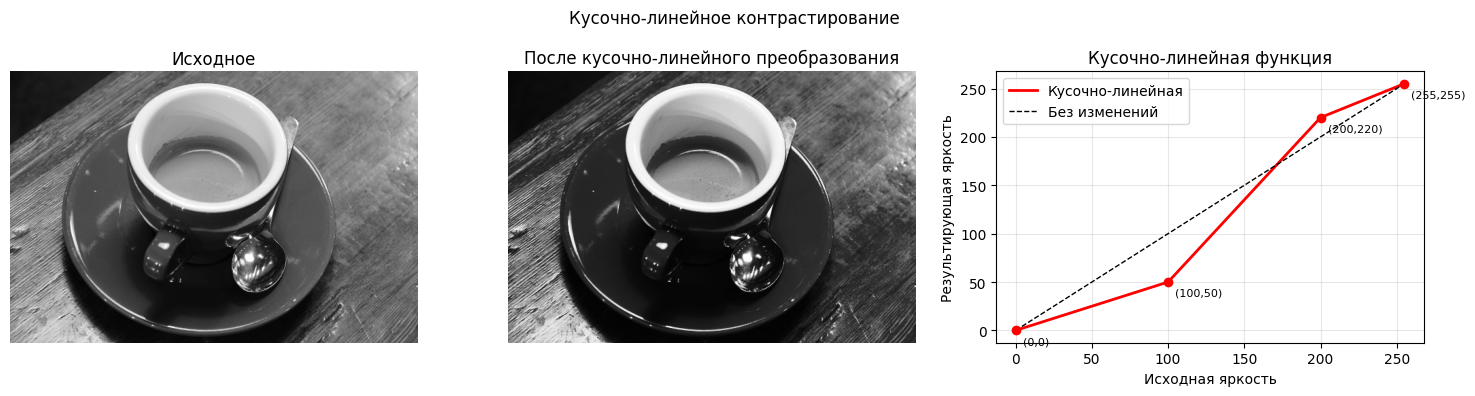

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
import cv2

img_rgb = data.coffee()
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Контрольные точки кусочно-линейной функции
xp = [0,   100, 200, 255]
fp = [0,    50, 220, 255]

# Применяем np.interp
gray_pwl = np.interp(gray.astype(np.float32), xp, fp).astype(np.uint8)

# Строим функцию преобразования
xvals = np.arange(0, 256)
yvals = np.interp(xvals, xp, fp)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Исходное')
axes[0].axis('off')

axes[1].imshow(gray_pwl, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('После кусочно-линейного преобразования')
axes[1].axis('off')

axes[2].plot(xvals, yvals, 'r-', linewidth=2, label='Кусочно-линейная')
axes[2].plot([0, 255], [0, 255], 'k--', linewidth=1, label='Без изменений')
for x, y in zip(xp, fp):
    axes[2].scatter(x, y, color='red', zorder=5)
    axes[2].annotate(f'({x},{y})', (x, y), textcoords='offset points',
                     xytext=(5, -10), fontsize=8)
axes[2].set_xlabel('Исходная яркость')
axes[2].set_ylabel('Результирующая яркость')
axes[2].set_title('Кусочно-линейная функция')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('Кусочно-линейное контрастирование')
plt.tight_layout()
plt.show()

**Вывод:** Наклон кусочно-линейной функции непосредственно определяет локальный контраст: там, где наклон больше 1 (участок 100–200 в результирующем: 50→220, наклон ≈ 1.7), разница между соседними значениями яркости увеличивается — контраст в этом диапазоне растёт. Где наклон меньше 1 (участок 0–100: 0→50, наклон = 0.5), детали в тёмной области «сжимаются» и теряются. Такой подход позволяет целенаправленно усилить контраст в интересующем диапазоне яркостей, пожертвовав деталями в других диапазонах.

### Задание 3.3. Гистограммы до и после кусочно-линейного преобразования
Постройте гистограммы яркости исходного и результирующего изображений (после кусочно-линейного преобразования). Прокомментируйте изменения.

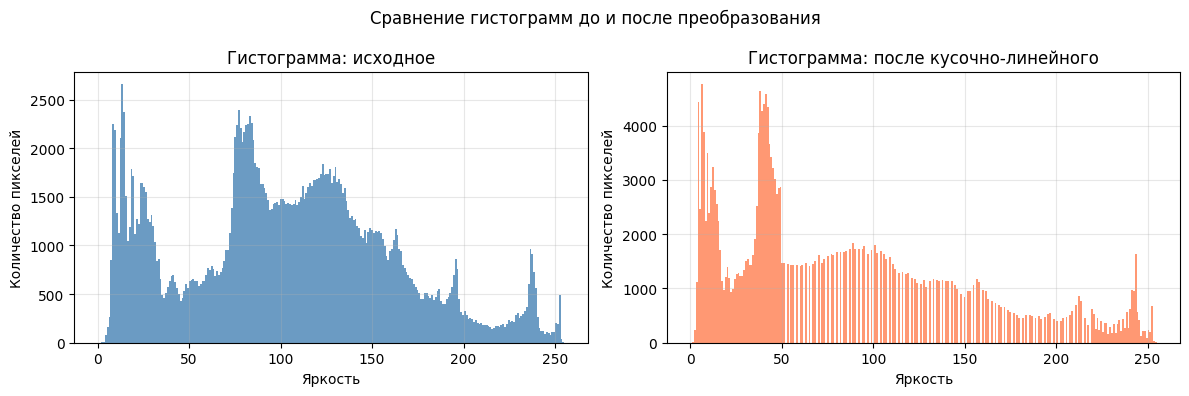

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
import cv2

img_rgb = data.coffee()
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

xp = [0, 100, 200, 255]
fp = [0,  50, 220, 255]
gray_pwl = np.interp(gray.astype(np.float32), xp, fp).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(gray.ravel(), bins=256, range=(0, 255), color='steelblue', alpha=0.8)
axes[0].set_title('Гистограмма: исходное')
axes[0].set_xlabel('Яркость')
axes[0].set_ylabel('Количество пикселей')
axes[0].grid(True, alpha=0.3)

axes[1].hist(gray_pwl.ravel(), bins=256, range=(0, 255), color='coral', alpha=0.8)
axes[1].set_title('Гистограмма: после кусочно-линейного')
axes[1].set_xlabel('Яркость')
axes[1].set_ylabel('Количество пикселей')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Сравнение гистограмм до и после преобразования')
plt.tight_layout()
plt.show()

**Вывод:** После кусочно-линейного преобразования гистограмма претерпевает характерные изменения: в тёмном диапазоне (0–50) пиксели сжимаются, гистограмма становится плотнее и выше в этой области. В светлом диапазоне (50–220 в результирующем) пиксели растягиваются, гистограмма сглаживается. Видны характерные «пробелы» (пустые столбцы) — следствие нелинейного растяжения: при масштабировании с коэффициентом > 1 некоторые значения яркости просто не встречаются после преобразования. Это типичный признак кусочно-линейного контрастирования с коэффициентом > 1.

### Задание 3.4. Эквализация гистограммы
Проведите эквализацию гистограммы через cv2.equalizeHist. Выведите гистограмму до и после.

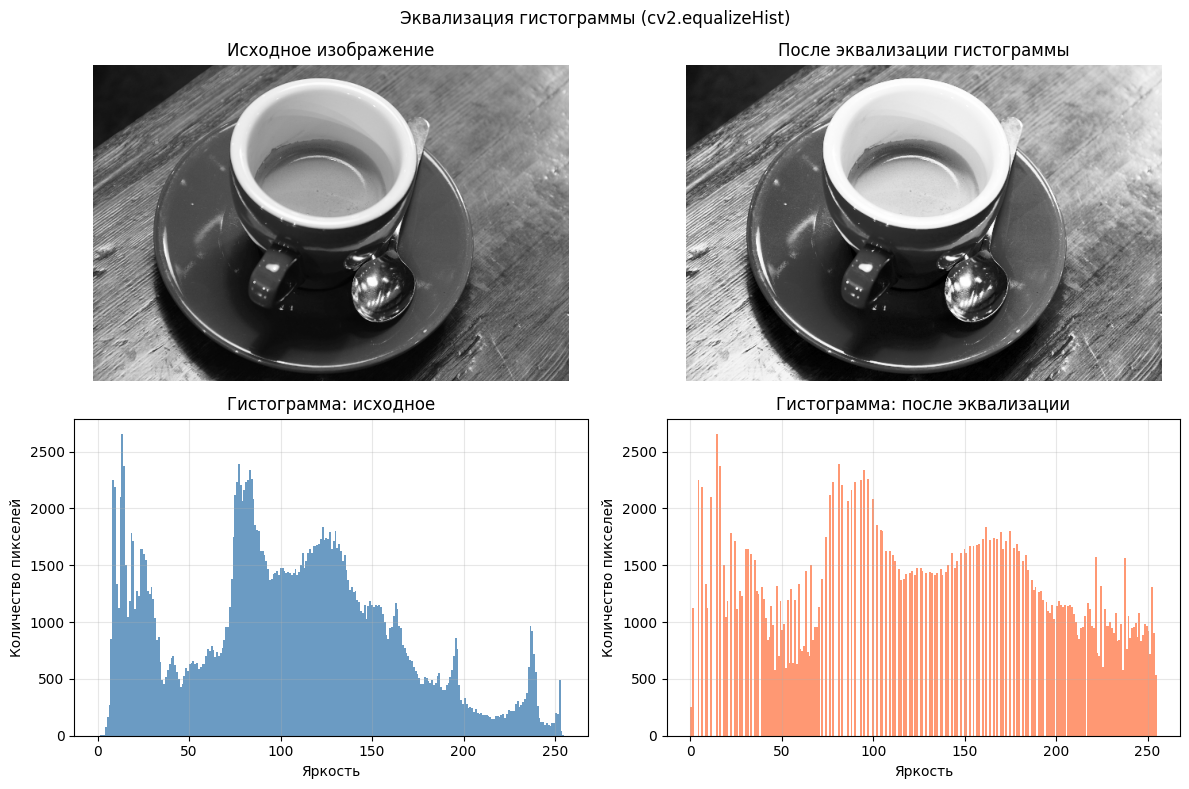

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
import cv2

img_rgb = data.coffee()
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

equalized = cv2.equalizeHist(gray)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(gray, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title('Исходное изображение')
axes[0, 0].axis('off')

axes[0, 1].imshow(equalized, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title('После эквализации гистограммы')
axes[0, 1].axis('off')

axes[1, 0].hist(gray.ravel(), bins=256, range=(0, 255), color='steelblue', alpha=0.8)
axes[1, 0].set_title('Гистограмма: исходное')
axes[1, 0].set_xlabel('Яркость')
axes[1, 0].set_ylabel('Количество пикселей')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].hist(equalized.ravel(), bins=256, range=(0, 255), color='coral', alpha=0.8)
axes[1, 1].set_title('Гистограмма: после эквализации')
axes[1, 1].set_xlabel('Яркость')
axes[1, 1].set_ylabel('Количество пикселей')
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('Эквализация гистограммы (cv2.equalizeHist)')
plt.tight_layout()
plt.show()

**Вывод:** Эквализация гистограммы перераспределяет яркости изображения таким образом, чтобы гистограмма стала как можно более равномерной. После операции гистограмма более равномерно охватывает весь диапазон [0, 255], что повышает глобальный контраст. На изображении лучше становятся видны детали как в тёмных, так и в светлых областях. Однако эквализация применяется глобально, поэтому в однородных областях может появляться шум, а насыщенные цвета могут изменить тон. Для цветных изображений рекомендуется применять эквализацию только к каналу яркости.

### Задание 3.5. Эквализация L-канала в пространстве LAB
Загрузите полноцветное изображение. Переведите в LAB. Проведите эквализацию только L-канала. Выведите результирующее изображение.

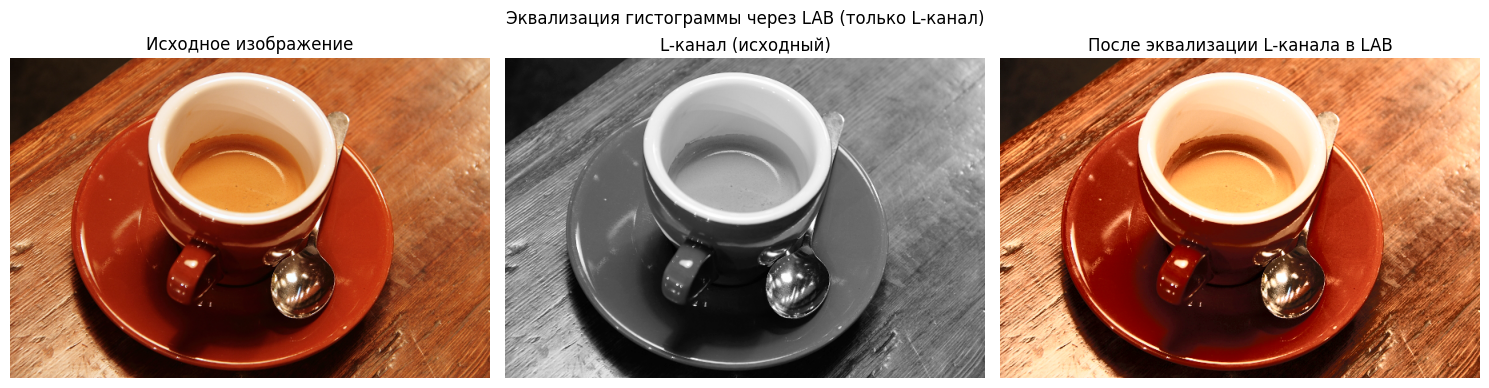

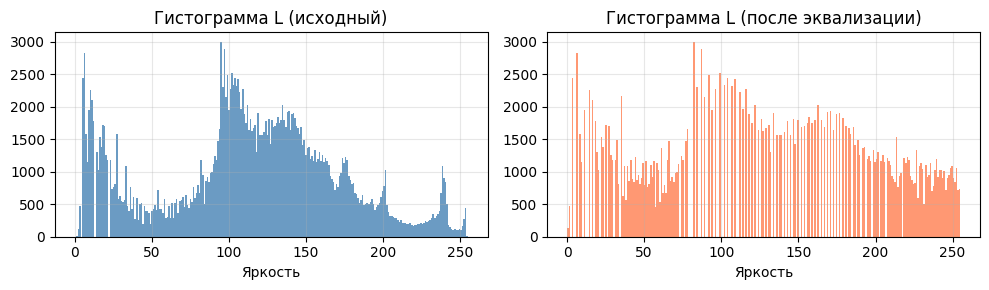

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
import cv2

img_rgb = data.coffee()
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)

# Перевод в LAB
lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
L, A, B = cv2.split(lab)

# Эквализация только L-канала
L_eq = cv2.equalizeHist(L)

# Сборка обратно
lab_eq = cv2.merge([L_eq, A, B])
result_bgr = cv2.cvtColor(lab_eq, cv2.COLOR_LAB2BGR)
result_rgb  = cv2.cvtColor(result_bgr, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(img_rgb)
axes[0].set_title('Исходное изображение')
axes[0].axis('off')

axes[1].imshow(L, cmap='gray')
axes[1].set_title('L-канал (исходный)')
axes[1].axis('off')

axes[2].imshow(result_rgb)
axes[2].set_title('После эквализации L-канала в LAB')
axes[2].axis('off')

plt.suptitle('Эквализация гистограммы через LAB (только L-канал)')
plt.tight_layout()
plt.show()

# Гистограммы L-канала до и после
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(L.ravel(), bins=256, range=(0, 255), color='steelblue', alpha=0.8)
axes[0].set_title('Гистограмма L (исходный)')
axes[0].set_xlabel('Яркость')
axes[0].grid(True, alpha=0.3)

axes[1].hist(L_eq.ravel(), bins=256, range=(0, 255), color='coral', alpha=0.8)
axes[1].set_title('Гистограмма L (после эквализации)')
axes[1].set_xlabel('Яркость')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Вывод:** Эквализация только L-канала в пространстве LAB — предпочтительный способ повышения контраста цветного изображения, поскольку яркость и цвет разделены. Каналы A и B (хроматические) остаются неизменными, поэтому цветовой тон и насыщенность не искажаются — в отличие от поканальной эквализации в RGB. Результат выглядит более естественно: детали проработаны лучше, а цвета не приобретают неестественных оттенков. Этот подход лежит в основе алгоритма CLAHE (адаптивной эквализации) и широко используется в медицинской визуализации.